# Gate CNN – demo notebook

Runs the gate-detection CNN for our autonomous drone project (Group 1).


## 1. Upload and unzip the project


In [1]:
from google.colab import files
uploaded = files.upload()          # choose gate_cnn.zip
!unzip -q -o gate_cnn.zip
%cd gate_cnn
!ls

Saving gate_cnn.zip to gate_cnn.zip
/content/gate_cnn
baseline.py  examples.png	   isaac_live.py   render.py	    train.py
config.py    Gate_CNN_demo.ipynb   label_isaac.py  results.json
detector.py  gate_cnn.npz	   nn_numpy.py	   results.png
evaluate.py  isaac_flight_cnn.mp4  README.md	   run_on_video.py


## 2. See the CNN find gates
Six random test images with the real gate size (1.5 m × 1.5 m opening, 0.2 m frame). Each title shows the distance the CNN estimated next to the true distance. Run it again for new images.

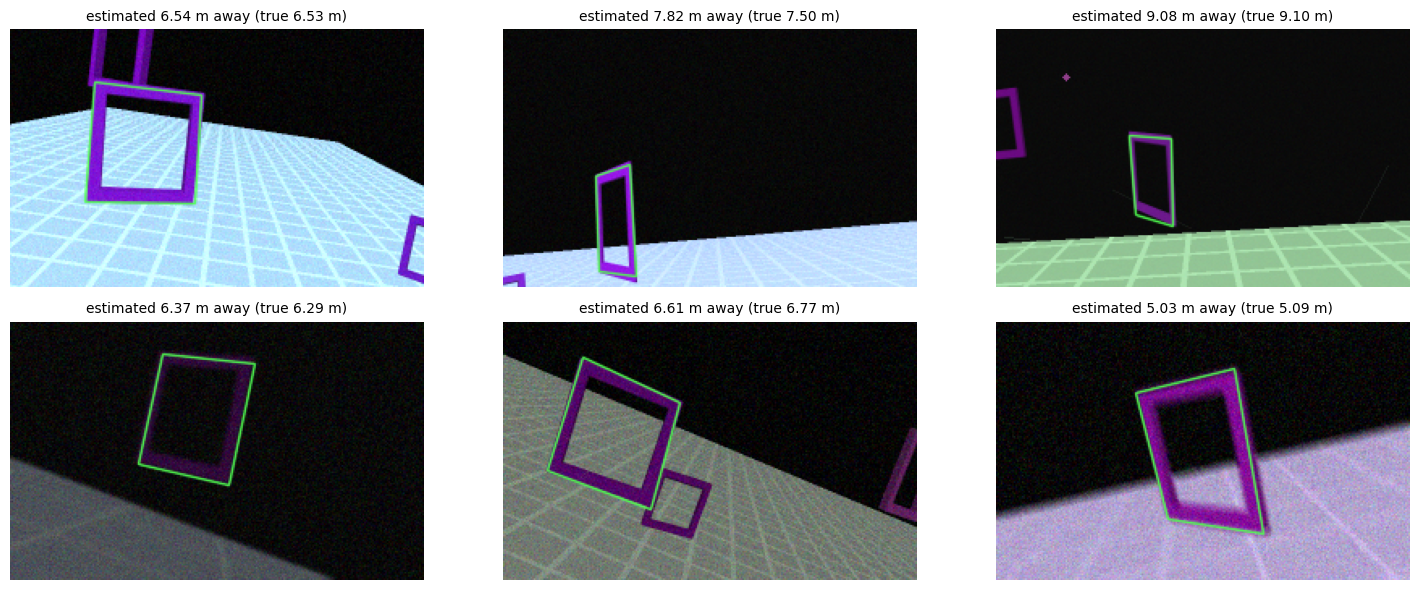

In [2]:
%matplotlib inline
import numpy as np, cv2, matplotlib.pyplot as plt
import config as C, render as R
from detector import GateCNN, good_detection, refine_with_colour, estimate_pose

cnn = GateCNN('gate_cnn.npz')
R.EXACT_GATE = True
rng = np.random.default_rng()
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax in axes.ravel():
    img, true_corners, gate = R.make_example(rng, aug=R.TRAIN_AUG, all_corners_in=True, distractors=(0, 2))
    corners, conf = cnn.detect(img)
    show = img.copy()
    title = 'no full gate found'
    if good_detection(img, corners, conf):
        corners = refine_with_colour(img, corners)
        ok, t, _ = estimate_pose(corners, C.intrinsics())
        cv2.polylines(show, [np.round(corners).astype(np.int32)], True, (80, 255, 80), 1, cv2.LINE_AA)
        title = f'estimated {np.linalg.norm(t):.2f} m away (true {np.linalg.norm(gate[1]):.2f} m)'
    ax.imshow(cv2.cvtColor(show, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=10); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. CNN vs color detector (quick version)
Runs the same comparison as the report on 40 images per condition (the report used 300; set `N_PER = 300` for the full run, about 2 minutes).

clean         cnn: 100.0% ok 1.23px | cnn+refine: 100.0% ok 1.29px | colour: 100.0% ok 1.29px
sensor noise  cnn: 100.0% ok 1.24px | cnn+refine: 100.0% ok 1.25px | colour: 100.0% ok 1.36px
motion blur   cnn: 100.0% ok 1.51px | cnn+refine: 100.0% ok 1.70px | colour:  97.5% ok 2.88px
low light     cnn: 100.0% ok 1.43px | cnn+refine: 100.0% ok 1.31px | colour: 100.0% ok 1.27px
clutter       cnn: 100.0% ok 1.25px | cnn+refine: 100.0% ok 1.28px | colour: 100.0% ok 1.69px
gates behind  cnn:  80.0% ok 5.61px | cnn+refine:  80.0% ok 5.57px | colour:  25.0% ok 14.90px
Isaac floor   cnn: 100.0% ok 1.24px | cnn+refine: 100.0% ok 1.41px | colour:  95.0% ok 2.43px
timing ms/frame {'cnn': 6.363986219678607, 'colour': 0.7058944020952498}


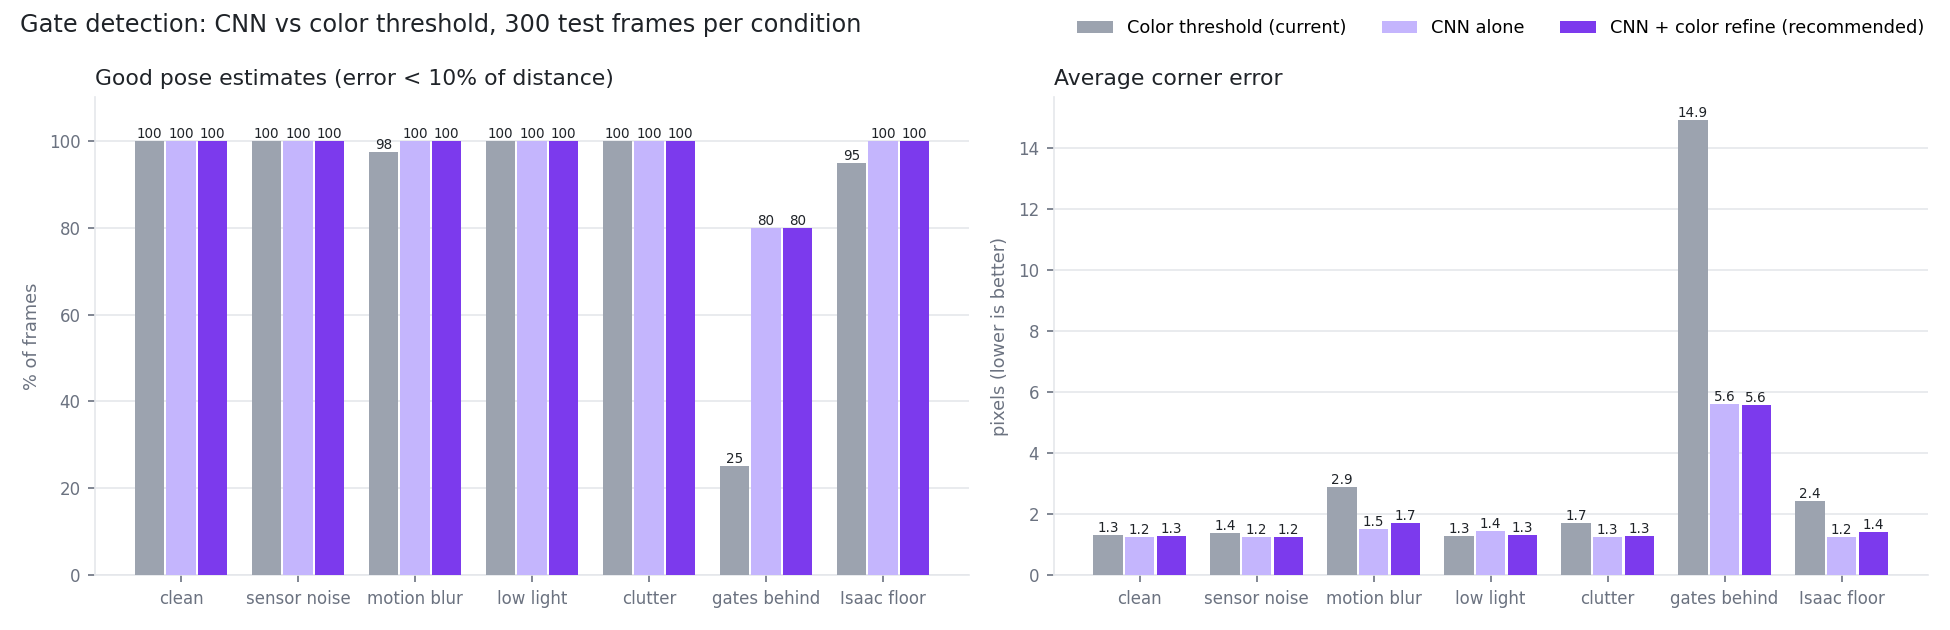

In [3]:
import evaluate
from IPython.display import Image, display
evaluate.N_PER = 40
evaluate.main()
display(Image('results.png'))

## 4. The CNN on Aaron's Isaac Sim flight
The annotated recording included in the project.

In [4]:
from IPython.display import HTML
from base64 import b64encode
def show_video(path):
    data = b64encode(open(path, 'rb').read()).decode()
    return HTML(f'<video width=640 controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')
show_video('isaac_flight_cnn.mp4')

## 5. Try it on your own video or images
Upload a video (`.mp4`, `.webm`) of the drone's front camera, or several `.png`/`.jpg` images. The result is an annotated video you can watch and download.

If the video is a **screen recording**, add `--crop x,y,w,h` to cut out just the camera view (for Aaron's recording that was `--crop 70,58,635,345`).

In [ ]:
import os, shutil
up = files.upload()
names = list(up)
if len(names) == 1 and names[0].lower().endswith(('.mp4', '.webm', '.mov', '.avi')):
    src = names[0]
else:
    os.makedirs('my_frames', exist_ok=True)
    for n in names: shutil.move(n, os.path.join('my_frames', n))
    src = 'my_frames'
!python run_on_video.py "{src}" --out my_result.mp4
show_video('my_result.mp4')

In [ ]:
files.download('my_result.mp4')